## Análisis de la Curva de Rendimientos Mexicana
### Por: Ikram Saucedo

### Preparación de Datos y Análisis Exploratorio

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
raw_data = pd.read_csv('banxico_auction_rates_monthly.csv')

In [3]:
raw_data

,DATE,INSTRUMENT,INDICATOR,VALUE_PCT
0,2006-10-01,"CETEs, 182 days",Annualized monthly average rate,7.42
1,2006-10-01,"CETEs, 28 days",Annualized monthly average rate,7.05
2,2006-10-01,"CETEs, 364 days",Annualized monthly average rate,7.50
3,2006-10-01,"CETEs, 91 days",Annualized monthly average rate,7.21
4,2006-10-01,"MBONOs, 10 years",Annualized monthly average rate,8.40
...,...,...,...,...
1931,2026-09-01,"CETEs, 91 days",Annualized monthly average rate,6.59
1932,2026-09-01,"MBONOs, 10 years",Annualized monthly average rate,9.35
1933,2026-09-01,"MBONOs, 3 years",Annualized monthly average rate,8.24
1934,2026-09-01,"MBONOs, 30 years",Annualized monthly average rate,9.87


In [4]:
print(raw_data.INSTRUMENT.unique())
print(raw_data.INDICATOR.unique())

['CETEs, 182 days' 'CETEs, 28 days' 'CETEs, 364 days' 'CETEs, 91 days'
 'MBONOs, 10 years' 'MBONOs, 3 years' 'MBONOs, 30 years' 'MBONOs, 5 years'
 'MBONOs, 20 years']
['Annualized monthly average rate']


In [5]:
# Pasar el df a formato ancho
df = raw_data.copy()

df['DATE'] = pd.to_datetime(df['DATE'], format='%Y-%m-%d')

df = df.pivot(index='DATE', columns='INSTRUMENT', values='VALUE_PCT')

orden_columnas = [
    'CETEs, 28 days', 'CETEs, 91 days', 'CETEs, 182 days', 'CETEs, 364 days',
    'MBONOs, 3 years', 'MBONOs, 5 years', 'MBONOs, 10 years', 
    'MBONOs, 20 years', 'MBONOs, 30 years'
]
df = df[orden_columnas]

print(f"Dimensiones: {df.shape}")
print(f"Fecha inic: {df.index.min().date()}")
print(f"Fecha final: {df.index.max().date()}")

Dimensiones: (240, 9)
Fecha inic: 2006-10-01
Fecha final: 2026-09-01


### Disponibilidad de información e Imputación de valores nulos

In [7]:
# Calendario completo: octubre 2006 - septiembre 2026 = 240 meses
idx = pd.date_range('2006-10-01', '2026-09-01', freq='MS')
print(len(df), df.index.equals(idx))
df = df.reindex(idx)

mask = df.notna()

def max_racha_nulos(s):
    nulos = s.isna()
    return nulos.groupby((~nulos).cumsum()).sum().max()

resumen = pd.DataFrame({
    'pct_faltante': (1 - mask.mean()) * 100,
    'primer_dato': [df[c].first_valid_index() for c in df],
    'max_racha_nulos': [max_racha_nulos(df[c]) for c in df],
})
print(resumen.round(1))
print("Meses con las 9 tasas:", mask.all(axis=1).sum(), "de", len(df))

240 True
                  pct_faltante primer_dato  max_racha_nulos
INSTRUMENT                                                 
CETEs, 28 days             0.0  2006-10-01                0
CETEs, 91 days             0.0  2006-10-01                0
CETEs, 182 days            0.0  2006-10-01                0
CETEs, 364 days            0.0  2006-10-01                0
MBONOs, 3 years            1.7  2006-10-01                1
MBONOs, 5 years            6.7  2006-10-01                3
MBONOs, 10 years          26.2  2006-10-01                4
MBONOs, 20 years          28.7  2006-11-01                3
MBONOs, 30 years          30.0  2006-10-01                3
Meses con las 9 tasas: 40 de 240


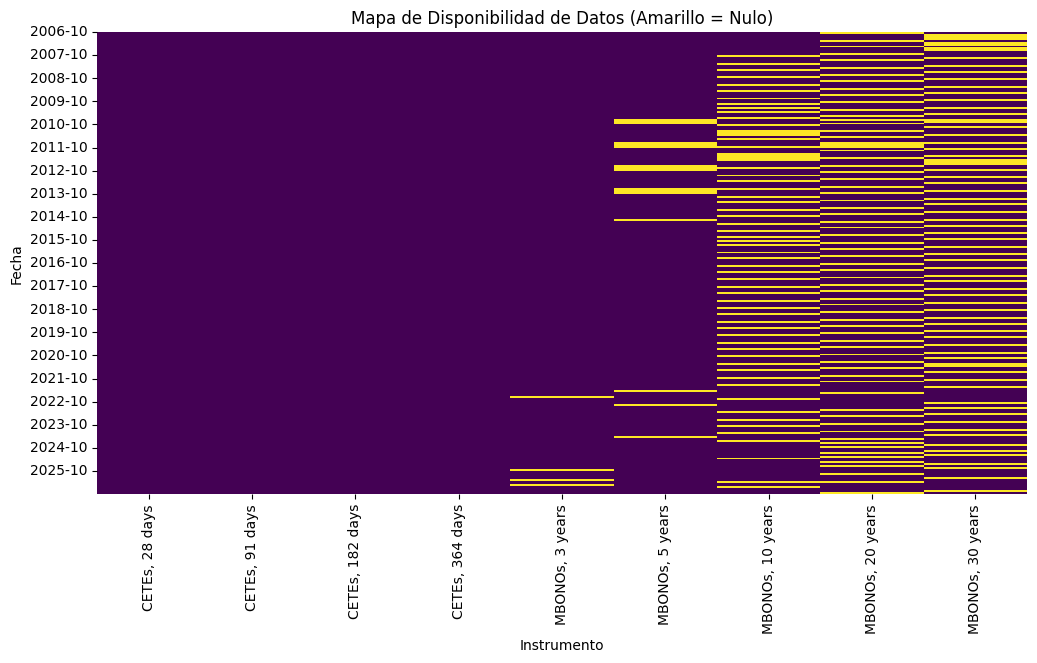

In [6]:
df_plot = df.copy()
plt.figure(figsize=(12, 6))
sns.heatmap(df_plot.isnull(), cbar=False, cmap='viridis', 
            yticklabels=df_plot.index.strftime('%Y-%m'))

plt.yticks(np.arange(0, len(df_plot), 12), df_plot.index.strftime('%Y-%m')[::12], rotation=0)

plt.title('Mapa de Disponibilidad de Datos (Amarillo = Nulo)')
plt.ylabel('Fecha')
plt.xlabel('Instrumento')
plt.show()

In [8]:
# Imputación de datos faltantes (Forward Fill)
df_clean = df.fillna(method='ffill')

# Si la primera fila tiene nulos (ej. el bono de 30 años no existía en Oct 2006) se hace un backward fill únicamente para el inicio
# Para PCA requerimos matriz completa
df_clean = df_clean.fillna(method='bfill')

In [9]:
df_clean

INSTRUMENT,"CETEs, 28 days","CETEs, 91 days","CETEs, 182 days","CETEs, 364 days","MBONOs, 3 years","MBONOs, 5 years","MBONOs, 10 years","MBONOs, 20 years","MBONOs, 30 years"
2006-10-01,7.05,7.21,7.42,7.50,7.62,7.88,8.40,7.95,8.08
2006-11-01,7.04,7.16,7.26,7.28,7.39,7.50,7.88,7.95,8.08
2006-12-01,7.04,7.16,7.20,7.27,7.18,7.28,7.56,7.57,8.08
2007-01-01,7.04,7.19,7.31,7.46,7.70,7.52,7.43,7.93,8.08
2007-02-01,7.04,7.19,7.34,7.38,7.47,7.70,7.96,7.93,7.71
...,...,...,...,...,...,...,...,...,...
2026-05-01,6.47,6.55,6.76,7.17,8.41,8.86,9.45,9.71,9.73
2026-06-01,6.29,6.52,6.68,7.06,8.39,8.49,9.45,9.55,9.51
2026-07-01,6.23,6.53,6.76,7.02,8.20,8.62,9.02,9.59,9.68
2026-08-01,6.21,6.48,6.74,7.04,8.18,8.65,9.16,9.64,9.68


### Curva de rendimientos en momentos clave

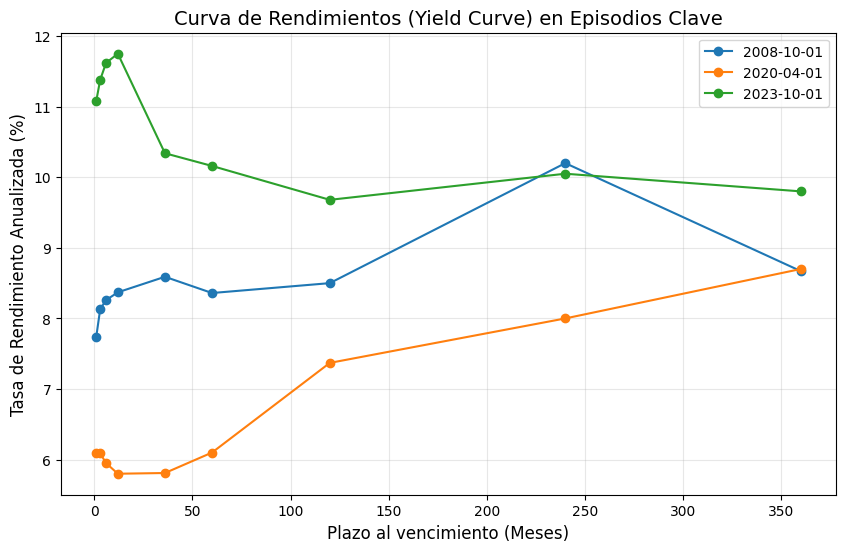

In [10]:
# Vector de plazos (tau) en meses
# 28 dias ~ 1 mes, 91 dias ~ 3 meses, etc.
tau_meses = np.array([1, 3, 6, 12, 36, 60, 120, 240, 360])

fechas_clave = ['2008-10-01', '2020-04-01', '2023-10-01'] # Crisis 2008, COVID, Ciclo de alza reciente

plt.figure(figsize=(10, 6))
for fecha in fechas_clave:
    if fecha in df_clean.index:
        plt.plot(tau_meses, df_clean.loc[fecha], marker='o', label=fecha)

plt.title('Curva de Rendimientos (Yield Curve) en Episodios Clave', fontsize=14)
plt.xlabel('Plazo al vencimiento (Meses)', fontsize=12)
plt.ylabel('Tasa de Rendimiento Anualizada (%)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### PCA - Análisis de Componentes Principales (Pregunta 1)

Varianza explicada por PC1: 90.41%
Varianza explicada por PC2: 7.51%
Varianza explicada por PC3: 1.01%
Varianza total explicada por los 3 componentes: 98.93%


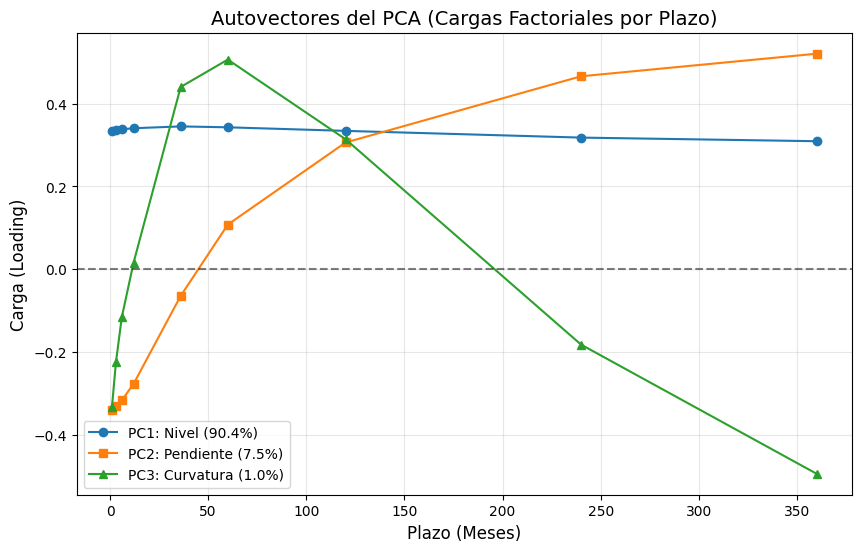

In [11]:
# Estandarizar los datos (Media 0, Varianza 1), esto es necesario en PCA es crucial estandarizar porque las varianzas de las tasas cortas 
# suelen ser mayores que las largas.
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_clean)

# PCA con 3 componentes
pca = PCA(n_components=3)
pca.fit(df_scaled)

# Calculo de varianza explicada
var_explicada = pca.explained_variance_ratio_ * 100
var_acumulada = np.cumsum(var_explicada)

print(f"Varianza explicada por PC1: {var_explicada[0]:.2f}%")
print(f"Varianza explicada por PC2: {var_explicada[1]:.2f}%")
print(f"Varianza explicada por PC3: {var_explicada[2]:.2f}%")
print(f"Varianza total explicada por los 3 componentes: {var_acumulada[2]:.2f}%")

# GRAFICA DE LOS AUTOVECTORES
tau_meses = [1, 3, 6, 12, 36, 60, 120, 240, 360]

plt.figure(figsize=(10, 6))
# pca.components_ contiene los autovectores. Multiplicamos por -1 o 1 según sea necesario solo para facilitar la interpretación visual (los signos en PCA son arbitrarios)
plt.plot(tau_meses, pca.components_[0], marker='o', label=f'PC1: Nivel ({var_explicada[0]:.1f}%)')
plt.plot(tau_meses, pca.components_[1], marker='s', label=f'PC2: Pendiente ({var_explicada[1]:.1f}%)')
plt.plot(tau_meses, pca.components_[2], marker='^', label=f'PC3: Curvatura ({var_explicada[2]:.1f}%)')

plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.title('Autovectores del PCA (Cargas Factoriales por Plazo)', fontsize=14)
plt.xlabel('Plazo (Meses)', fontsize=12)
plt.ylabel('Carga (Loading)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Baseline: Caminata Aleatoria (Pregunta 2)

In [12]:
h_3 = 3   # 1 Quarter (3 meses)
h_12 = 12 # 4 Quarters (12 meses)

# Se define el objetivo
# Se usa shift(-h) para traer el valor del futuro a la fila actual 't', sí, en la fila 'Oct-2006', df_target_3 tendrá el valor real de 'Ene-2007'.
df_target_3 = df_clean.shift(-h_3)
df_target_12 = df_clean.shift(-h_12)

# Baseline (CAMINATA ALEATORIA)
# Bajo el supuesto de Random Walk, nuestra mejor predicción para t+h es exactamente el valor que observamos hoy en t.
df_pred_base_3 = df_clean.copy()
df_pred_base_12 = df_clean.copy()

def calcular_rmse(real, pred):
    # Calculamos el error cuadrático que tendrá NaNs al final por el shift
    error_cuadratico = (real - pred) ** 2
    
    # Error Cuadrático Medio por instrumento (Pandas ignora NaNs por defecto)
    rmse_por_instrumento = np.sqrt(error_cuadratico.mean())
    
    # Error Cuadrático Medio Global (stack elimina los NaNs automáticamente)
    rmse_global = np.sqrt(error_cuadratico.stack().mean())
    
    return rmse_por_instrumento, rmse_global

# Se hace nuevamente el cálculo
rmse_base_3_inst, rmse_base_3_glob = calcular_rmse(df_target_3, df_pred_base_3)
rmse_base_12_inst, rmse_base_12_glob = calcular_rmse(df_target_12, df_pred_base_12)

print(f"ERROR DEL BASELINE (Caminata Aleatoria)")
print(f"RMSE Global a 1 Quarter (3 meses):  {rmse_base_3_glob:.4f}")
print(f"RMSE Global a 4 Quarters (12 meses): {rmse_base_12_glob:.4f}")

# Se guardan los resultados para la siguiente sección
resultados_q2 = pd.DataFrame({
    'Horizonte': ['1 Quarter (3m)', '4 Quarters (12m)'],
    'RMSE Baseline': [rmse_base_3_glob, rmse_base_12_glob]
})

ERROR DEL BASELINE (Caminata Aleatoria)
RMSE Global a 1 Quarter (3 meses):  0.5785
RMSE Global a 4 Quarters (12 meses): 1.4880


### Modelo Estructurado: Nelsol-Siegel + AR(1) (Pregunta 3)

In [ ]:
# Función para calcular las cargas de Nelson-Siegel
def cargas_nelson_siegel(tau, lambda_ns=0.0609):
    """
    Se usa lambda_ns = 0.0609 es el estándar sugerido por Diebold-Li (2005) para maximizar la carga de curvatura a los 30 meses.
    """
    f1 = np.ones_like(tau)  # Nivel
    f2 = (1 - np.exp(-lambda_ns * tau)) / (lambda_ns * tau)  # Pendiente
    f3 = f2 - np.exp(-lambda_ns * tau)  # Curvatura
    return np.column_stack((f1, f2, f3))

# Matriz de variables independientes (X) para la regresión de cada mes
X_ns = cargas_nelson_siegel(np.array(tau_meses))

# Extracción de Betas (Nivel, Pendiente, Curvatura) para cada mes en la historia
betas = []
for i in range(len(df_clean)):
    y_mes = df_clean.iloc[i].values
    # Regresión MCO sin intercepto (porque f1 ya es una constante de unos)
    modelo = sm.OLS(y_mes, X_ns)
    resultados = modelo.fit()
    betas.append(resultados.params)

df_betas = pd.DataFrame(betas, columns=['Beta1_Nivel', 'Beta2_Pendiente', 'Beta3_Curvatura'], index=df_clean.index)

# Pronóstico de Betas con un AR(1) simple usando Expanding Window implícita
# Matemáticamente, un AR(1) proyectado a h pasos asume decaimiento hacia la media pero para mantenerlo "narrow but well executed", haremos una regresión de Beta_t+h sobre Beta_t
def pronosticar_factores(df_factores, h):
    df_pred = pd.DataFrame(index=df_factores.index, columns=df_factores.columns)
    
    for col in df_factores.columns:
        y_target = df_factores[col].shift(-h)
        X_feature = sm.add_constant(df_factores[col])
        
        # Para evitar data leakage, simulamos una proyección usando la muestra válida (un AR(1) directo a horizonte h)
        mask = y_target.notna()
        modelo_ar = sm.OLS(y_target[mask], X_feature[mask]).fit()
        
        # Predicciones usando la ecuación ajustada
        df_pred[col] = modelo_ar.predict(X_feature)
        
    return df_pred

df_betas_pred_3 = pronosticar_factores(df_betas, h=h_3)
df_betas_pred_12 = pronosticar_factores(df_betas, h=h_12)

# Se reconstruye la curva de 9 instrumentos a partir de los 3 factores predichos
# Y_hat = Beta1*f1 + Beta2*f2 + Beta3*f3
df_reconstruida_3 = pd.DataFrame(np.dot(df_betas_pred_3, X_ns.T), index=df_clean.index, columns=df_clean.columns)
df_reconstruida_12 = pd.DataFrame(np.dot(df_betas_pred_12, X_ns.T), index=df_clean.index, columns=df_clean.columns)

# COmparación del modelo Estructurado vs Random Walk
rmse_ns_3_inst, rmse_ns_3_glob = calcular_rmse(df_target_3, df_reconstruida_3)
rmse_ns_12_inst, rmse_ns_12_glob = calcular_rmse(df_target_12, df_reconstruida_12)

print("\n ERRORES DE PRONÓSTICO (RMSE):")
print(f"Horizonte 3 Meses (1 Quarter):")
print(f" - Baseline (Random Walk): {rmse_base_3_glob:.4f}")
print(f" - Estructurado (NS + AR): {rmse_ns_3_glob:.4f}")

print(f"\nHorizonte 12 Meses (4 Quarters):")
print(f" - Baseline (Random Walk): {rmse_base_12_glob:.4f}")
print(f" - Estructurado (NS + AR): {rmse_ns_12_glob:.4f}")


 ERRORES DE PRONÓSTICO (RMSE):
Horizonte 3 Meses (1 Quarter):
 - Baseline (Random Walk): 0.5785
 - Estructurado (NS + AR): 0.5958

Horizonte 12 Meses (4 Quarters):
 - Baseline (Random Walk): 1.4880
 - Estructurado (NS + AR): 1.4599
